# Wine Quality Prediction
**Oasis Infobyte SIP — Data Analytics L2 Task 2** · Steven Manuel Rios

Dataset: **Wine Quality**, UCI ML Repository (id 186; Cortez et al., 2009): physicochemical tests on 1,599 red and 4,898 white *vinho verde* wines, each with a sensory quality score from 0 to 10. This notebook uses the **red wine** set, the one usually used for this task. The white set is kept in `data/`.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
sns.set_theme(style="whitegrid")
def save(name): plt.tight_layout(); plt.savefig(f"screenshots/{name}.png", dpi=110); plt.show()

In [2]:
df = pd.read_csv("data/winequality-red.csv", sep=";")
print(df.shape); print(df.isnull().sum().sum(), "nulls |", df.duplicated().sum(), "duplicate rows (kept: identical measurements of different wines are plausible)")
df["quality"].value_counts().sort_index()

(1599, 12)
0 nulls | 240 duplicate rows (kept: identical measurements of different wines are plausible)


quality
3     10
4     53
5    681
6    638
7    199
8     18
Name: count, dtype: int64

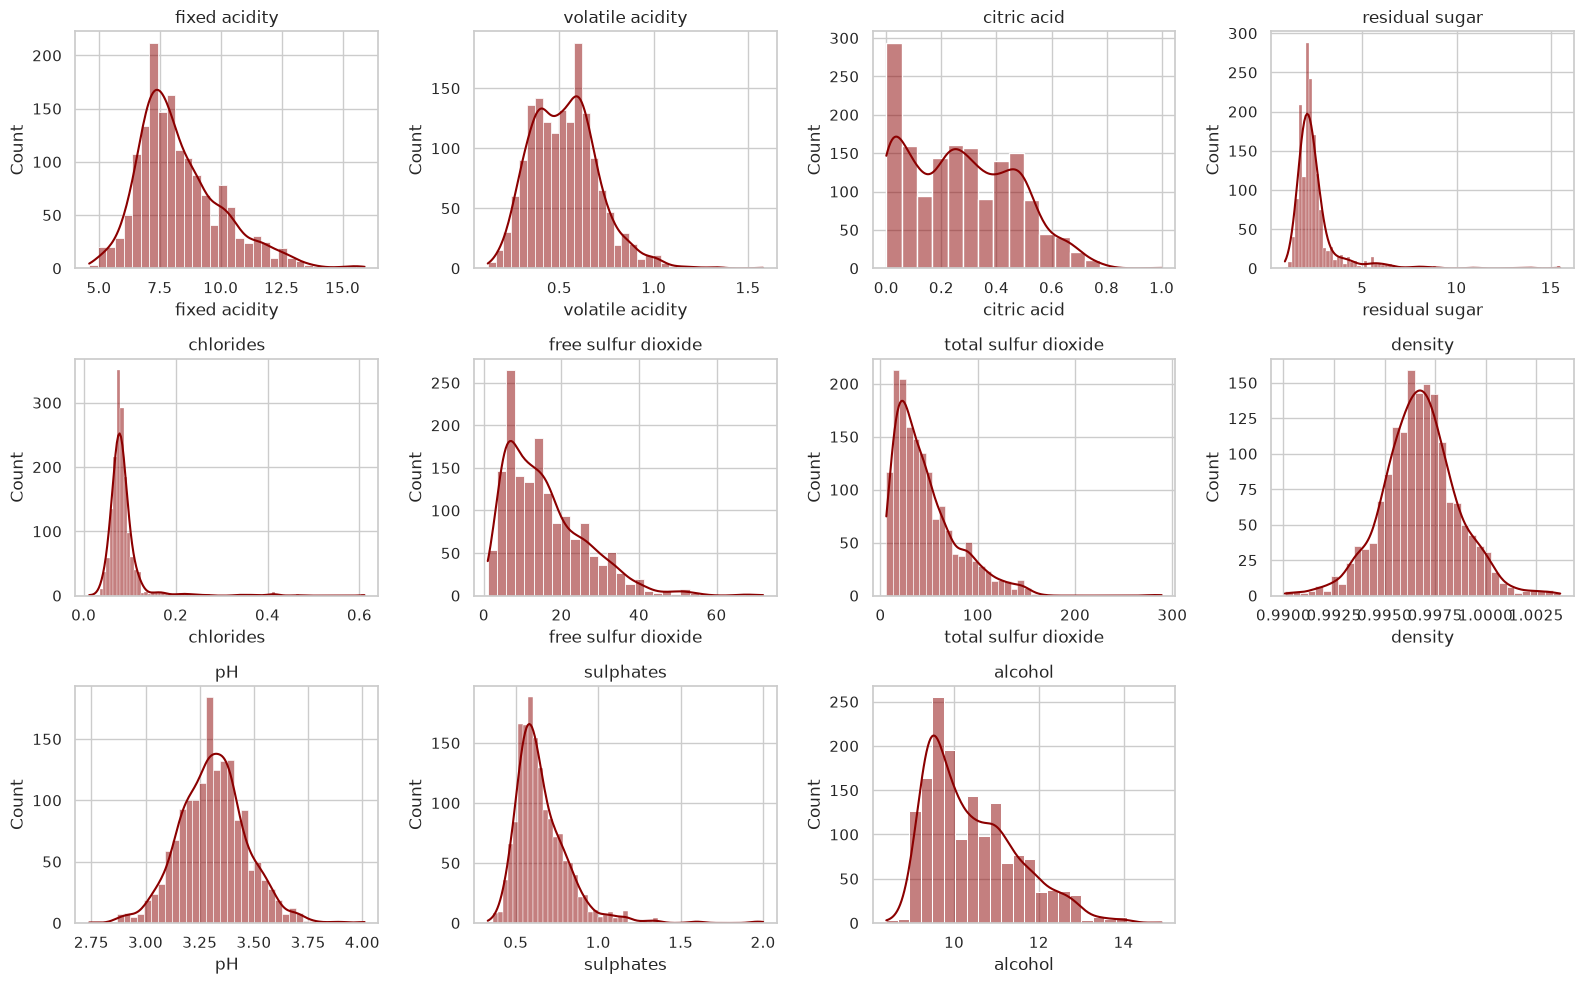

In [3]:
feats = df.columns.drop("quality")
fig, axes = plt.subplots(3, 4, figsize=(16, 10))
for ax, col in zip(axes.flat, feats): sns.histplot(df[col], kde=True, ax=ax, color="darkred"); ax.set_title(col)
axes.flat[-1].axis("off"); save("feature_distributions")

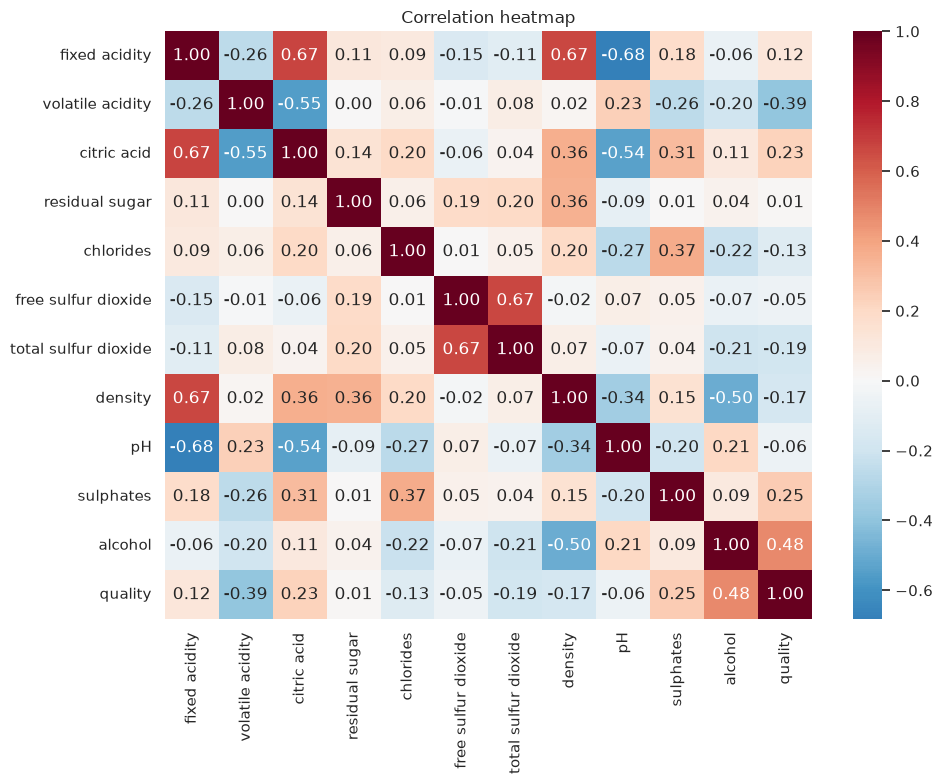

volatile acidity       -0.391
total sulfur dioxide   -0.185
density                -0.175
chlorides              -0.129
pH                     -0.058
free sulfur dioxide    -0.051
residual sugar          0.014
fixed acidity           0.124
citric acid             0.226
sulphates               0.251
alcohol                 0.476
Name: quality, dtype: float64

In [4]:
plt.figure(figsize=(10, 8)); sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0); plt.title("Correlation heatmap"); save("correlation")
df.corr()["quality"].drop("quality").sort_values().round(3)

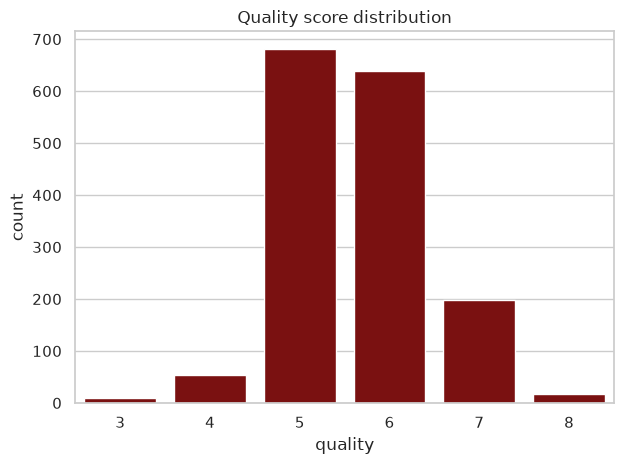

In [5]:
sns.countplot(x=df["quality"], color="darkred"); plt.title("Quality score distribution"); save("quality_distribution")

## Class imbalance
Scores 5 and 6 make up **82%** of the wines, while 3 (10 wines), 4 (53) and 8 (18) are rare. A 6-class model would mostly learn to predict 5 or 6. Rare classes would have almost no recall, and accuracy would look good while being meaningless for the wines that matter, the excellent and the poor ones.

## Feature engineering: binning
Quality is binned into **3 classes**: `low` (3–4), `medium` (5–6) and `high` (7–8). This keeps the business-relevant distinction between flagging poor wines and identifying premium ones, which a binary split would lose for poor wines. The medium class is still dominant, so `class_weight='balanced'` is used where supported, and stratification keeps the class ratios in both splits.

In [6]:
df["grade"] = pd.cut(df["quality"], [0, 4, 6, 10], labels=["low", "medium", "high"])
print(df["grade"].value_counts())
from sklearn.model_selection import train_test_split
X, y = df[feats], df["grade"]
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=.2, stratify=y, random_state=42)

grade
medium    1319
high       217
low         63
Name: count, dtype: int64


===== Random Forest =====
               precision    recall  f1-score   support

         low      0.000     0.000     0.000        13
      medium      0.886     0.973     0.928       264
        high      0.767     0.535     0.630        43

    accuracy                          0.875       320
   macro avg      0.551     0.503     0.519       320
weighted avg      0.834     0.875     0.850       320

===== SGD =====
               precision    recall  f1-score   support

         low      0.059     0.231     0.094        13
      medium      0.894     0.765     0.824       264
        high      0.488     0.488     0.488        43

    accuracy                          0.706       320
   macro avg      0.480     0.495     0.469       320
weighted avg      0.805     0.706     0.750       320

===== SVC =====
               precision    recall  f1-score   support

         low      0.130     0.231     0.167        13
      medium      0.919     0.769     0.837       264
        high  

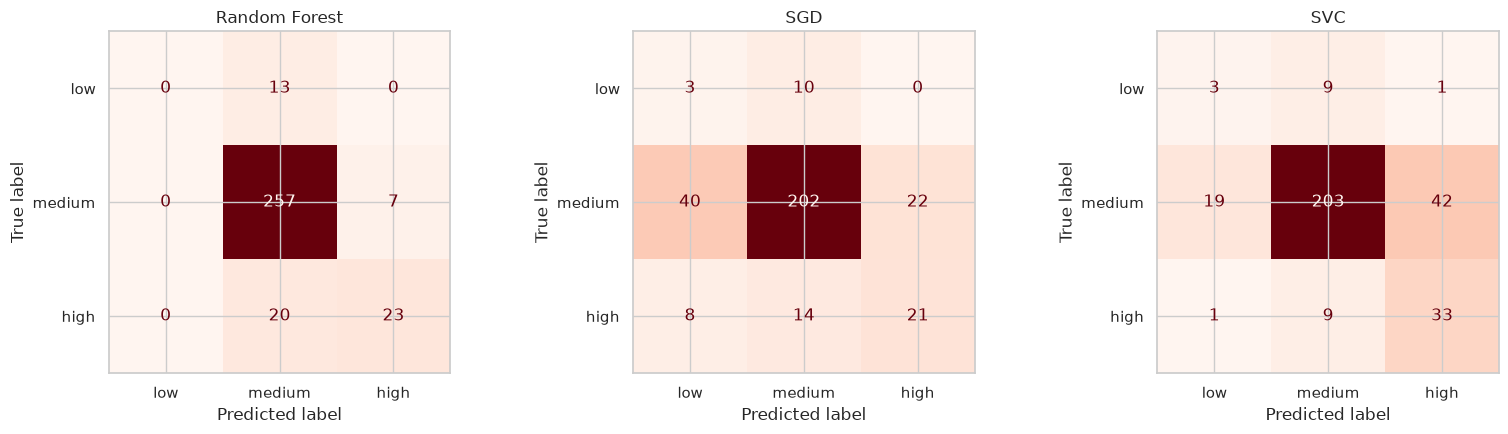

In [7]:
from sklearn.ensemble import RandomForestClassifier; from sklearn.linear_model import SGDClassifier; from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler; from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay, f1_score, balanced_accuracy_score
models = {"Random Forest": RandomForestClassifier(400, class_weight="balanced_subsample", random_state=42, n_jobs=-1),
          "SGD": make_pipeline(StandardScaler(), SGDClassifier(loss="log_loss", class_weight="balanced", max_iter=2000, random_state=42)),
          "SVC": make_pipeline(StandardScaler(), SVC(C=3, gamma="scale", class_weight="balanced", random_state=42))}
labels = ["low", "medium", "high"]; rows = {}
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
for a, (n, m) in zip(ax, models.items()):
    p = m.fit(Xtr, ytr).predict(Xte)
    print(f"===== {n} =====\n", classification_report(yte, p, labels=labels, digits=3))
    ConfusionMatrixDisplay(confusion_matrix(yte, p, labels=labels), display_labels=labels).plot(ax=a, colorbar=False, cmap="Reds"); a.set_title(n)
    rows[n] = {"accuracy": accuracy_score(yte, p), "balanced accuracy": balanced_accuracy_score(yte, p), "macro F1": f1_score(yte, p, average="macro"), "high-class recall": (p[yte == "high"] == "high").mean()}
save("confusion_matrices")

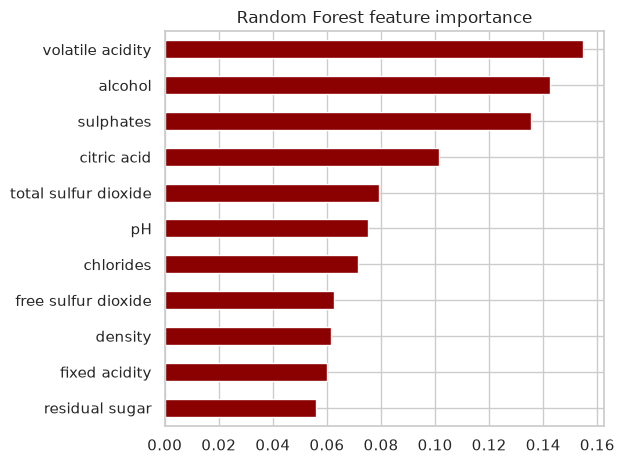

volatile acidity        0.155
alcohol                 0.142
sulphates               0.136
citric acid             0.101
total sulfur dioxide    0.079
pH                      0.075
chlorides               0.071
free sulfur dioxide     0.063
density                 0.062
fixed acidity           0.060
residual sugar          0.056
dtype: float64

In [8]:
imp = pd.Series(models["Random Forest"].feature_importances_, index=feats).sort_values()
imp.plot.barh(color="darkred"); plt.title("Random Forest feature importance"); save("feature_importance"); imp[::-1].round(3)

## Comparison table

In [9]:
comp = pd.DataFrame(rows).T.round(3); comp

,accuracy,balanced accuracy,macro F1,high-class recall
Random Forest,0.875,0.503,0.519,0.535
SGD,0.706,0.495,0.469,0.488
SVC,0.747,0.589,0.519,0.767


## Conclusion
* **Random Forest** has the highest accuracy (**87.5%**) but only because it predicts *medium* almost always. It catches 0 of the 13 low-quality wines and 54% of the high-quality ones.
* **SVC (RBF, class-balanced)** has the same macro F1 (0.519) and the best **balanced accuracy (0.589)**. It finds **77% of premium wines** and 23% of poor ones, at the cost of more false alarms (accuracy 74.7%).
* **SGD** (a linear model) is the weakest: accuracy 70.6%, macro F1 0.469.
* The most important features are **volatile acidity** (vinegar taint, negative), **alcohol** and **sulphates** (positive), which matches the correlation heatmap.

**Deployment choice:** if the goal is to *flag premium or poor batches* for a winemaker or retailer, deploy the **SVC**, because its minority-class recall is far better and accuracy is misleading here. If the goal is simply the most correct labels overall, Random Forest wins. Either way, the low class (63 wines in total) is too small to learn well, and more data or oversampling would be the next step.